# Netflix Data Analysis — Exploratory Data Analysis (EDA)

This project explores the Netflix catalog dataset to identify patterns and trends in Movies and TV Shows.

The analysis focuses on understanding the structure and characteristics of the dataset, cleaning and preprocessing the data, and using exploratory data analysis and visualization to investigate content types, ratings, genres, countries, release years, durations, and other relevant patterns.

## Dataset Overview

The dataset contains information about Netflix Movies and TV Shows, including:

- Title
- Content type
- Director
- Cast
- Country
- Date added
- Release year
- Rating
- Duration
- Genres
- Description

The dataset contains **8,807 records and 12 columns** in its original form. It includes both Movies and TV Shows and contains missing values in several columns, which are handled during the data-cleaning stage.

This analysis treats the dataset as a catalog snapshot rather than a live representation of the current Netflix catalog.

## Libraries and Setup

The following Python libraries are used for data analysis and visualization:

- **Pandas** — data loading, cleaning, transformation, and analysis
- **NumPy** — numerical operations
- **Matplotlib** — data visualization
- **Seaborn** — statistical and exploratory visualizations

In [169]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("../data/netflix_titles.csv")


DATA EXAMINATION AND OBSERVATION BEFORE PERFORMING OPERATION

In [170]:
df.head(5)

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [ ]:
df.tail(5)

In [ ]:
df.info()

In [ ]:
df.describe()

In [ ]:
df.isnull().sum()

In [ ]:
df.duplicated().sum()

In [ ]:
df["type"].value_counts()

#Data cleaning and preprocessinhg

#Created a working copy of the original dataset to preserve the raw data.

In [ ]:
df_clean = df.copy()

In [ ]:
df_clean.head()

Standardized column names for consistency.

In [ ]:
df_clean.columns = df_clean.columns.str.strip().str.lower()

Handled missing categorical values in director, cast, country, and rating by labeling them as "Unknown".

In [ ]:
df_clean["cast"] = df_clean["cast"].fillna("Unknown")
df_clean["country"] = df_clean["country"].fillna("Unknown")
df_clean["director"] = df_clean["director"].fillna("Unknown")
df_clean["rating"] = df_clean["rating"].fillna("Unknown")

Converted date_added from text to a proper datetime format. due to their format use %B %d, %Y b for complete month name. Can check your date format in dataset first.

In [ ]:

df_clean["date_added"] = pd.to_datetime(
    df_clean["date_added"], 
    format="%B %d, %Y", 
    errors="coerce"
)


In [ ]:
df_clean["date_added"].isnull().sum()

check for missing values afetr performing some cleaning operations 

In [ ]:
df_clean.isnull().sum()

check for how much and which are missing values in the duration 

In [ ]:
df_clean[df_clean["duration"].isnull()][
    ["title", "type", "duration"]
]

check for duratio column data 

In [ ]:
df_clean["duration"].value_counts().head(20)

Separated the duration column into two variables:

duration_value — numerical value of the duration.

duration_unit — whether the value represents minutes or seasons. because later it will be easy to perform numerical operations on duration 

extract integer value from the duration text and change it into numbers 

In [ ]:
df_clean["duration_value"] = df_clean["duration"].str.extract(r"(\d+)")[0]

df_clean["duration_value"] = pd.to_numeric(
    df_clean["duration_value"],
    errors="coerce"
)

exract units 

In [ ]:
df_clean["duration_unit"] = df_clean["duration"].str.extract(
    r"([A-Za-z]+)"
)[0]

In [ ]:
df_clean[["type", "duration", "duration_value", "duration_unit"]].head(10)

Correcting inconsistent duration/rating entries

there is season for 1 season and seasons for multiple seasons so for consistency replace season with seasons 

In [ ]:
df_clean["duration_unit"] = df_clean["duration_unit"].replace(
    {"Season": "Seasons"}
)

In [ ]:
df_clean["duration_unit"].value_counts()

In [ ]:
df_clean.duplicated().sum()

Removed show_id because it is only an identifier and does not contribute to the planned analysis.

Removed description because this project focuses on structured data analysis rather than text/NLP analysis.

In [ ]:
df_clean =df_clean.drop(
    columns=["show_id", "description"]
)

Performed a final check of the dataset's structure, data types, missing values, and duplicates.
Kept the small number of genuinely missing date_added and duration values rather than introducing inaccurate information.

In [ ]:
df_clean.columns

In [ ]:
df_clean.shape

In [ ]:
df_clean.info()

The cleaned dataset is now ready for exploratory data analysis (EDA).

# Exploratory Data Analysis (EDA)

Exploratory Data Analysis is used to understand the main characteristics, patterns, and relationships within the Netflix catalog.

The analysis will be guided by specific questions rather than creating visualizations without a purpose. Each question will be explored using appropriate Pandas analysis and, where useful, Matplotlib or Seaborn visualizations.

The main areas of analysis include:

- Content type — Movies vs TV Shows
- Ratings and content classification
- Genres
- Countries
- Release-year trends
- Movie durations and TV-show seasons
- Changes in the catalog over time
- Relationships between content type, ratings, countries, and genres
- The age of titles when they were added to Netflix



In [ ]:
#ANALYSIS

1. How many Movies and TV Shows are in the Netflix catalog?

In [ ]:
type_counts = df_clean["type"].value_counts()

type_counts

Step 1 — Calculate percentages

In [ ]:
type_percentage = (type_counts / len(df_clean) * 100).round(2)

type_percentage

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.bar(type_percentage.index, type_percentage.values,
         color=["#E50914", "#564D4D"])

plt.title("Movies vs TV Shows on Netflix")
plt.xlabel("Content Type")
plt.ylabel("Percentage of Titles")

plt.show()

In [ ]:
plt.figure(figsize=(5, 5))

plt.pie(
    type_percentage.values,
    labels=type_percentage.index,
    autopct="%.2f%%",
    startangle=90,
    colors=["#E50914", "#564D4D"]
)

plt.title("Movies vs TV Shows on Netflix")

plt.show()

### Question 1 ,Insight:

By analyzing the charts, we can interpret that Movies have a significantly higher proportion than TV Shows in the dataset. The pie chart shows that approximately **70% of the titles are Movies, while 30% are TV Shows**, indicating that Movies make up the larger share of the overall Netflix catalog represented in this dataset.

In [ ]:
rating_counts = df_clean["rating"].value_counts()

rating_counts

In [ ]:
df_clean[df_clean["rating"].isin(["74 min", "84 min", "66 min"])]

In [ ]:
mask = df_clean["rating"].str.contains("min", na=False)

df_clean.loc[mask, "duration"] = df_clean.loc[mask, "rating"]
df_clean.loc[mask, "rating"] = "Unknown"

In [ ]:
df_clean.loc[mask, ["title", "rating", "duration"]]

In [ ]:
df_clean.loc[mask, "duration_value"] = pd.to_numeric(
    df_clean.loc[mask, "duration"].str.extract(r"(\d+)")[0],
    errors="coerce"
)

df_clean.loc[mask, "duration_unit"] = (
    df_clean.loc[mask, "duration"].str.extract(r"([A-Za-z]+)")[0]
)

In [ ]:
df_clean.loc[
    mask,
    ["title", "rating", "duration", "duration_value", "duration_unit"]
]

Q2 — What are the most common ratings?

In [ ]:
rating_counts = df_clean["rating"].value_counts()
rating_counts

Which content ratings appear most frequently in the Netflix catalog?

In [ ]:
top_ratings = rating_counts.head(10)
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 7))

colors = [
    "#E50914",
    "#D71920",
    "#C41E2A",
    "#AD1F2F",
    "#962032",
    "#7F2135",
    "#682238",
    "#51233B",
    "#3A243E",
    "#232541"
]

plt.barh(
    top_ratings.index,
    top_ratings.values,
    color=colors
)
#===== Add values at the end of each bar======
"""goes through each bar and gets:
- i → position of the bar
- value → actual number of titles"""
for i, value in enumerate(top_ratings.values):
    plt.text(
        value + 20,
        i,
        str(value),
        va="center"
    )

plt.title("Top 10 Netflix Content Ratings")
plt.xlabel("Number of Titles")
plt.ylabel("Rating")

plt.gca().invert_yaxis()

plt.show()

### Question 2 ,Insight:

By analyzing the chart, we can interpret that **TV-MA is the most common rating** in the dataset, with 3,207 titles, which is significantly higher than the other ratings. The chart also shows that **TV-MA, TV-14, and TV-PG** are the three most common ratings, indicating that these ratings represent a large portion of the content in the dataset.

Q3 — What are the most common genres?

SEPARATE THE GENRES FIRST 

In [ ]:
df_clean["listed_in"].head(10)

In [ ]:
#SPlit the Genre first
genres = df_clean["listed_in"].str.split(", ")

In [ ]:
genres.head()

In [ ]:
#count individual genre. explode is use for this pupose so each genre gets its own count 
genre_counts = genres.explode().value_counts()

genre_counts.head(10)

Step 1 — Select the top 10 genres

In [ ]:
top_genres = genre_counts.head(10)

top_genres
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 7))

colors = [
    "#E50914",  
    "#FF6B6B", 
    "#FFA94D",
    "#FFD43B",
    "#69DB7C",
    "#38D9A9",
    "#4DABF7",
    "#748FFC",
    "#B197FC",
    "#F783AC" 
]

plt.barh(
    top_genres.index,
    top_genres.values,
    color=colors
)

# Add numbers to the bars
for i, value in enumerate(top_genres.values):
    plt.text(
        value + 20,
        i,
        str(value),
        va="center"
    )

plt.title("Top 10 Genres on Netflix")
plt.xlabel("Number of Titles")
plt.ylabel("Genre")

plt.gca().invert_yaxis()

plt.show()

### Question 3 , Insight:

By analyzing the data and observing the chart, we can interpret that **International Movies are the most common genre**, with 2,752 titles, which is significantly higher than the other genres shown. The chart also shows that **International Movies, Dramas, Comedies, and International TV Shows** are the four most common genres in the dataset.

Q4 — Which countries have the most Netflix titles?

The country column is similar to listed_in: a title can belong to multiple countries.
so perform same operations as listed in first split then explode function 


In [ ]:
countries = df_clean["country"].str.split(", ")
countries.head()
country_counts = countries.explode().value_counts()

country_counts.head(10)

Clean the country ranking for visualization

-As we can see  831 countries are unknown 

-Since Unknown represents missing country information, remove it only from this country-specific analysis. We don't need to change df_clean.

In [ ]:
country_counts_known = country_counts.drop("Unknown")

top_countries = country_counts_known.head(10)

top_countries

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 7))

colors = [
    "#264653",
    "#2A9D8F",
    "#E9C46A",
    "#F4A261",
    "#E76F51",
    "#457B9D",
    "#6D597A",
    "#B56576",
    "#43AA8B",
    "#577590"
]

plt.barh(
    top_countries.index,
    top_countries.values,
    color=colors
)

for i, value in enumerate(top_countries.values):
    plt.text(
        value + 30,
        i,
        str(value),
        va="center"
    )

plt.title("Top 10 Countries by Number of Netflix Titles")
plt.xlabel("Number of Titles")
plt.ylabel("Country")

plt.gca().invert_yaxis()

plt.show()

###  Question 4 ,Insight:

By analyzing the data and observing the chart, we can interpret that the **United States is the country associated with the highest number of titles**, with 3,689 titles, which is significantly higher than the other countries shown. However, this does not mean that all of these titles were produced solely by the United States, because a single title can be associated with multiple countries. Therefore, the results represent the number of titles associated with each country rather than titles produced exclusively by that country.

Q5 — Which release years have the most titles?

In [ ]:
release_year_counts = df_clean["release_year"].value_counts().sort_index()

release_year_counts.head()
#find top 10 release years
top_release_years = df_clean["release_year"].value_counts().head(10).sort_index()

top_release_years

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

plt.plot(
    top_release_years.index,
    top_release_years.values,
    marker="o",
    linewidth=3,
    color="green"
)

for year, value in zip(top_release_years.index, top_release_years.values):
    plt.text(
        year,
        value + 20,
        str(value),
        ha="center"
    )

plt.title("Top Release Years by Number of Netflix Titles")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")

plt.xticks(top_release_years.index, rotation=45)

plt.show()

### Question 5, Insight:

By analyzing the line chart, we can interpret that the chart represents the **top 10 release years with the highest number of titles** in the dataset. The number of titles increases significantly from 2012 to 2018, reaching the highest point in **2018 with 1,147 titles**. After 2018, the number of titles gradually decreases, reaching 592 titles in 2021.

Q6 — How are movie durations distributed?

for this we will only use movies because our drama type contains seasons not numerical time duration 

In [ ]:
movies = df_clean[df_clean["type"] == "Movie"]
movies["duration_value"].describe()

As movies durations are of very close and of small intervals it becomes difficult to read 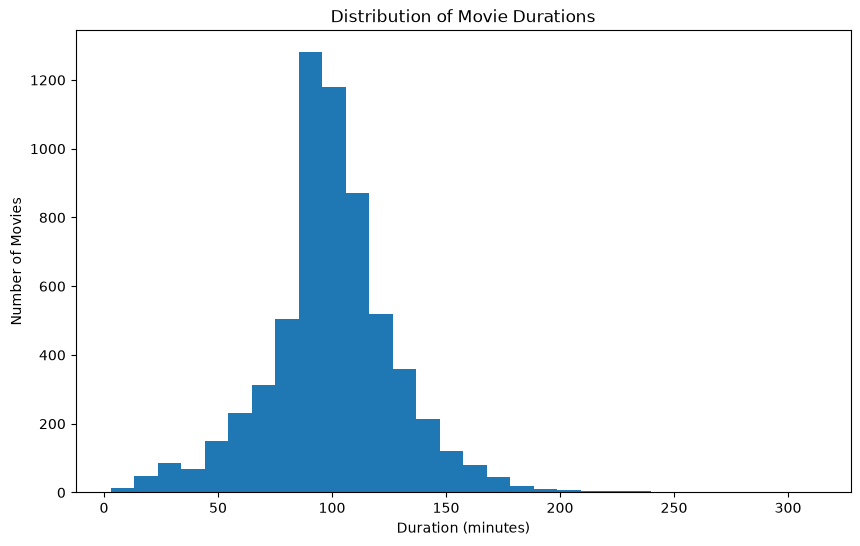 

as you can see from here , so better appraoch is to divide time duration into group intervals  so it becomes easy to understand and interpret the insight 

In [ ]:
duration_bins = [0, 60, 90, 120, 150, 180, float("inf")]

duration_labels = [
    "Under 60",
    "60–89",
    "90–119",
    "120–149",
    "150–179",
    "180+"
]

movies["duration_group"] = pd.cut(
    movies["duration_value"],
    bins=duration_bins,
    labels=duration_labels,
    right=False
)

duration_groups = movies["duration_group"].value_counts().sort_index()

duration_groups
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

colors = [
    "#457B9D",
    "#2A9D8F",
    "#E9C46A",
    "#F4A261",
    "#E76F51",
    "#9B5DE5"
]

plt.bar(
    duration_groups.index,
    duration_groups.values,
    color=colors
)

for i, value in enumerate(duration_groups.values):
    plt.text(
        i,
        value + 20,
        str(value),
        ha="center"
    )

plt.title("Distribution of Netflix Movie Durations")
plt.xlabel("Movie Duration")
plt.ylabel("Number of Movies")

plt.xticks(rotation=20)

plt.show()

###Question 6 ,Insight:

By carefully analyzing the data and the chart, we can interpret that the **90–119 minute range is the most common movie duration**, containing 3,092 movie titles. This analysis focuses only on Movies because TV Shows are represented by the number of seasons rather than a numerical duration in minutes. Therefore, the duration distribution was analyzed separately for Movies. The chart shows that most movie titles in the dataset have a duration between **90 and 119 minutes**.

Q7 — Has the Movies vs TV Shows balance changed over time?

pd.crosstab() is useful because it counts combinations of two categorical variables.

In [ ]:
type_by_year = pd.crosstab(
    df_clean["release_year"],
    df_clean["type"]
)

type_by_year.tail(10)

In [ ]:
recent_type_by_year = type_by_year.loc[2000:2021]

recent_type_by_year

In [ ]:
recent_type_by_year = pd.crosstab(
    df_clean["release_year"],
    df_clean["type"]
).loc[2000:2021]

plt.figure(figsize=(11, 6))

plt.plot(
    recent_type_by_year.index,
    recent_type_by_year["Movie"],
    marker="o",
    label="Movies"
)

plt.plot(
    recent_type_by_year.index,
    recent_type_by_year["TV Show"],
    marker="o",
    label="TV Shows"
)

plt.title("Movies vs TV Shows by Release Year (2000–2021)")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")

plt.legend()

plt.show()

### Question 8,Insight:

After analyzing the chart, we can observe that both Movies and TV Shows generally show an increasing trend in the number of titles from 2000 onward. However, their trends differ in the later years. **Movies reach their highest number around 2017–2018 and then gradually decrease**, while **TV Shows continue increasing after 2018 and reach their highest point around 2020 before decreasing in 2021**. This shows that the distribution of Movies and TV Shows varies across different release years.

Q8 — Do Movies and TV Shows have different rating patterns?

In [ ]:
rating_by_type = pd.crosstab(
    df_clean["rating"],
    df_clean["type"]
)

rating_by_type

In [ ]:
rating_percentage = rating_by_type.div(
    rating_by_type.sum(axis=0),
    axis=1
) * 100

rating_percentage = rating_percentage.round(2)

rating_percentage

In [ ]:
main_ratings = [
    "TV-MA",
    "TV-14",
    "TV-PG",
    "TV-Y",
    "TV-Y7",
    "TV-G",
    "R",
    "PG-13",
    "PG",
    "G"
]

rating_comparison = rating_percentage.loc[main_ratings]
rating_comparison.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Rating Distribution: Movies vs TV Shows")
plt.xlabel("Rating")
plt.ylabel("Percentage of Titles")
plt.xticks(rotation=45)

plt.legend(title="Content Type")

plt.show()

###Question 8, Insight:

After analyzing the chart, we can interpret that **TV-MA has the highest proportion among both Movies and TV Shows**. However, when comparing the two content types, **TV Shows have a higher proportion of TV-MA titles than Movies**. This indicates that TV-MA content represents a larger share of the TV Show catalog compared with its share of the Movie catalog.

Q9 — Do major countries differ in Movies vs TV Shows?

same operation as a country title contains multiple countries in its rows


Because one title can have multiple countries, explode() creates multiple rows with the same original index.
So when pd.crosstab() tries to align the two Series, a duplicate reindex error occurs so uses reset_indes after explode 

In [ ]:
country_data = df_clean.assign(
    country=df_clean["country"].str.split(", ")
).explode("country").reset_index(drop=True)

not deleting anythinng just removing or filtering unknown countries from this particular analysis 

In [ ]:
country_data = country_data[
    country_data["country"].notna() &
    (country_data["country"] != "") &
    (country_data["country"] != "Unknown")
]

In [ ]:
country_type = pd.crosstab(
    country_data["country"],
    country_data["type"]
)

country_type.head(20)

In [ ]:
top_country_names = country_counts_known.head(10).index

In [ ]:
top_country_type = country_type.loc[top_country_names]

top_country_type

In [ ]:
country_type_percentage = (
    top_country_type
    .div(top_country_type.sum(axis=1), axis=0)
    * 100
).round(2)

country_type_percentage

In [ ]:
import matplotlib.pyplot as plt

country_type_percentage.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 6),
    color=["#E76F51", "#2A9D8F"]
)

plt.title("Movie vs TV Show Composition by Country")
plt.xlabel("Country")
plt.ylabel("Percentage of Titles")

plt.xticks(rotation=45, ha="right")

plt.legend(title="Content Type")

plt.tight_layout()

plt.show()

### Question 9,Insight:

By analyzing the chart, we can observe that **India has a particularly high proportion of Movie titles**, while countries such as Japan and South Korea have a considerably larger proportion of TV Shows. Overall, the major countries shown in the analysis differ in their distribution of Movies and TV Shows, although some countries have relatively similar Movie proportions.

However, this analysis is based only on titles with known country information, as the `Unknown` country values were excluded. Therefore, the results should be interpreted as a comparison of the **selected countries represented in the dataset**, rather than a complete representation of all countries in the Netflix catalog.

Q10 — Is the Netflix catalog mainly recent or older content?

In [ ]:
release_bins = [0, 2000, 2010, 2015, 2020, 2022]

release_labels = [
    "Before 2000",
    "2000–2009",
    "2010–2014",
    "2015–2019",
    "2020–2021"
]

df_clean["release_period"] = pd.cut(
    df_clean["release_year"],
    bins=release_bins,
    labels=release_labels,
    right=False
)
release_period_counts = df_clean["release_period"].value_counts().sort_index()

release_period_counts

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(
    release_period_counts.index,
    release_period_counts.values,
    color=[
        "#457B9D",
        "#2A9D8F",
        "#E9C46A",
        "#F4A261",
        "#E76F51"
    ]
)

for i, value in enumerate(release_period_counts.values):
    plt.text(
        i,
        value + 50,
        str(value),
        ha="center"
    )

plt.title("Netflix Titles by Release Period")
plt.xlabel("Release Period")
plt.ylabel("Number of Titles")

plt.xticks(rotation=20)

plt.show()

###Question 10, Insight:

After analyzing the chart, we can interpret that a large portion of the Netflix catalog represented in the dataset consists of relatively recent content. The **2015–2019 release period has the highest number of titles, with 4,671 titles**, which is significantly higher than the other release periods. This indicates that the dataset is largely concentrated around titles released during the more recent years.

Q11 — How old were titles when they were added to Netflix?

In [ ]:
#===claculate the age of content when it was added to Netflix======
df_clean["age_when_added"] = (
    df_clean["date_added"].dt.year
    - df_clean["release_year"]
)

In [ ]:
df_clean["age_when_added"].describe()

In [ ]:
df_clean[
    df_clean["age_when_added"] < 0
][
    ["title", "release_year", "date_added", "age_when_added"]
]

In [ ]:
df_clean["age_when_added_clean"] = df_clean["age_when_added"].where(
    df_clean["age_when_added"] >= 0
)

In [ ]:
df_clean["age_when_added_clean"].describe()

In [ ]:
age_bins = [-1, 0, 1, 3, 6, 11, float("inf")]

age_labels = [
    "Same year",
    "1 year",
    "2–3 years",
    "4–6 years",
    "7–11 years",
    "12+ years"
]

df_clean["addition_age_group"] = pd.cut(
    df_clean["age_when_added_clean"],
    bins=age_bins,
    labels=age_labels
)
age_group_counts = (
    df_clean["addition_age_group"]
    .value_counts()
    .sort_index()
)

age_group_counts

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(
    age_group_counts.index,
    age_group_counts.values,
    color=[
        "#264653",
        "#2A9D8F",
        "#E9C46A",
        "#F4A261",
        "#E76F51",
        "#6D597A"
    ]
)

for i, value in enumerate(age_group_counts.values):
    plt.text(
        i,
        value + 50,
        str(value),
        ha="center"
    )

plt.title("Age of Titles When Added to Netflix")
plt.xlabel("Time Between Release and Netflix Addition")
plt.ylabel("Number of Titles")

plt.xticks(rotation=20)

plt.show()

### Question 11,Insight:

By analyzing the chart, we can interpret that **titles added to Netflix in the same year as their release have the highest count**, with 3,222 titles. This is considerably higher than the other age groups. However, this analysis has a limitation because some titles in the dataset produced negative age values, meaning their recorded Netflix addition date was earlier than their recorded release year. These values were excluded from this specific age analysis. Therefore, based on the valid age values analyzed, the **same-year category represents the largest group of titles**.

Q12 — Which directors have the most titles on Netflix?

In [ ]:
director_counts = (
    df_clean[df_clean["director"] != "Unknown"]["director"]
    .value_counts()
    .head(10)
)

plt.figure(figsize=(10, 6))

plt.barh(
    director_counts.index[::-1],
    director_counts.values[::-1],
   color = [
    "#5C0000",
    "#750000",
    "#8F0000",
    "#A80000",
    "#C00000",
    "#D31616",
    "#E02B2B",
    "#EB4A4A",
    "#F36B6B",
    "#FA8C8C"
]
)

for i, value in enumerate(director_counts.values[::-1]):
    plt.text(
        value + 0,
        i,
        str(value),
        va="center"
    )

plt.title("Top 10 Directors by Number of Titles")
plt.xlabel("Number of Titles")
plt.ylabel("Director")
plt.xticks(range(0, 21, 5))
plt.tight_layout()
plt.show()

### Question 12, Insight:

After analyzing the chart, we can interpret that Rajiv Chilaka has the highest number of titles among the directors shown, with 19 titles, followed by **Raúl Campos and Jan Suter with 18 titles**. However, this analysis excludes titles where the director information was recorded as Unknown. Therefore, based on the available director information in the dataset, Rajiv Chilaka has the highest number of titles among the directors represented in this analysis.

Q13 — Which actors appear most frequently?

In [ ]:
cast_data = df_clean.assign(
    actor=df_clean["cast"].str.split(", ")
).explode("actor").reset_index(drop=True)
cast_data = cast_data[
    cast_data["actor"].notna() &
    (cast_data["actor"] != "Unknown") &
    (cast_data["actor"] != "")
]

In [ ]:
actor_counts = (
    cast_data["actor"]
    .value_counts()
    .head(10)
)

actor_counts

In [ ]:
colors = [
    "#264653",
    "#315A68",
    "#3F6F7D",
    "#4F8290",
    "#6095A0",
    "#72A8AF",
    "#84B9BD",
    "#96C8C9",
    "#A9D6D4",
    "#BBD9D7"
]

plt.figure(figsize=(10, 6))

plt.barh(
    actor_counts.index[::-1],
    actor_counts.values[::-1],
    color=colors
)

for i, value in enumerate(actor_counts.values[::-1]):
    plt.text(
        value + 1,
        i,
        str(value),
        va="center"
    )

plt.title("Top 10 Actors by Number of Titles")
plt.xlabel("Number of Titles")
plt.ylabel("Actor")

plt.tight_layout()
plt.show()

### Question 13 , Insight:

After analyzing the chart, we can interpret that **Anupam Kher has the highest number of titles among the actors shown, with 43 titles**, followed by **Shah Rukh Khan with 35 titles**. However, this analysis excludes titles where the actor information was recorded as `Unknown`. Therefore, based on the available actor information, **Anupam Kher has the highest number of titles among the actors represented in this analysis**.

Q14 — Which genres are most common within Movies vs TV Shows?

In [ ]:
genre_data = df_clean.assign(
    genre=df_clean["listed_in"].str.split(", ")
).explode("genre")

movie_genres = (
    genre_data[genre_data["type"] == "Movie"]["genre"]
    .value_counts()
    .head(10)
)

tv_genres = (
    genre_data[genre_data["type"] == "TV Show"]["genre"]
    .value_counts()
    .head(10)
)
plt.figure(figsize=(10, 6))

plt.barh(
    movie_genres.index[::-1],
    movie_genres.values[::-1],
    color="#4F8290"
)

for i, value in enumerate(movie_genres.values[::-1]):
    plt.text(
        value + 20,
        i,
        str(value),
        va="center"
    )

plt.title("Top 10 Genres Among Movies")
plt.xlabel("Number of Titles")
plt.ylabel("Genre")

plt.tight_layout()
plt.show()

### question 14, part A, Insight:

After analyzing the chart, we can interpret that **International Movies is the most common genre among Movies**, with 2,752 titles, followed by **Dramas with 2,427 titles**. This shows that these two genres have the highest number of titles among the movie genres represented in the analysis.

In [ ]:
plt.figure(figsize=(10, 6))

plt.barh(
    tv_genres.index[::-1],
    tv_genres.values[::-1],
    color="#84B9BD"
)

for i, value in enumerate(tv_genres.values[::-1]):
    plt.text(
        value + 10,
        i,
        str(value),
        va="center"
    )

plt.title("Top 10 Genres Among TV Shows")
plt.xlabel("Number of Titles")
plt.ylabel("Genre")

plt.tight_layout()
plt.show()

### question 14,part B, Insight:

After analyzing the chart, we can interpret that **International TV Shows are the most common genre among TV Shows**, with 1,351 titles, followed by **TV Dramas with 763 titles**. TV Comedies are the third most common genre, with 581 titles. Overall, International TV Shows have a considerably higher number of titles than the other TV Show genres represented in the analysis.

END 

## 7. Key Findings

The exploratory analysis identified several notable patterns in the Netflix catalog:

- Movies represent the larger share of the dataset, accounting for approximately **69.62%** of titles.
- **TV-MA** is the most common content rating.
- **International Movies** is the most common genre category overall.
- The **United States** is associated with the highest number of titles among the countries analyzed.
- **2018** has the highest number of titles among the release years analyzed.
- Most movies fall within the **90–119 minute** duration range.
- Titles released and added to Netflix in the **same year** form the largest age group.
- **Rajiv Chilaka** has the highest number of titles among the available director data.
- **Anupam Kher** has the highest number of titles among the available actor data.
- Movies generally dominate the catalog, although TV Shows show a stronger presence in more recent release years.

## 8. Limitations

This analysis has several limitations that should be considered when interpreting the results:

- The dataset represents a **catalog snapshot** and does not represent the current Netflix catalog.
- Several records contain missing information, particularly for directors, cast, and countries.
- Some titles are associated with multiple countries and genres, so counts can exceed the total number of titles.
- The `release_year` represents the original release year of the title and should not be interpreted as the year it was added to Netflix.
- The analysis of age when added to Netflix contains a small number of inconsistent negative values, which were excluded from that specific analysis without removing the original records.
- Country, director, and actor analyses are based only on the information available in the dataset.

# Final Conclusion

This exploratory data analysis provided an overall understanding of the Netflix catalog represented in the dataset. After cleaning the data and handling missing and inconsistent values, different aspects of the catalog were analyzed, including content types, ratings, genres, countries, release years, durations, addition patterns, directors, and actors.

The analysis shows that **Movies represent the larger share of the dataset, accounting for approximately 69.62% of the titles, while TV Shows account for 30.38%**. TV-MA was the most common rating, while International Movies was the most common genre overall. The United States was associated with the highest number of titles among the countries analyzed. The release-year analysis showed that the number of titles was particularly high in recent years, with 2018 having the highest number of titles among the years analyzed. Most movies had a duration between **90 and 119 minutes**, while titles added in the same year as their release formed the largest age group.

The analysis also identified Rajiv Chilaka as the director with the highest number of titles among the available director data and Anupam Kher as the actor with the highest number of titles among the available actor data.

Overall, the analysis demonstrates how data cleaning, exploratory analysis, and visualization can be used to identify meaningful patterns while also considering the limitations and structure of the dataset.